# Recipe Recommendations: Collaborative Filtering, Clustering, and Content Based Methods on Food.com
### Project Goal and Overview
In the space of online food recipes, there are seemingly endless possibilities of new recipes to try. This project seeks to provide accurate recipe rating predictions and recipe recommendations using various methods.

Author: Vidhya Walke
Dataset: Food.com Recipes and Interactions (180K+ recipes, 1.13M+ reviews spanning 18 years)
Reference Paper: Bodhisattwa Prasad Majumder, Shuyang Li, Jianmo Ni, Julian McAuley. Generating Personalized Recipes from Historical User Preferences, EMNLP, 2019


## 1. Imports and Environment Setup


In [1]:
import os
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('default')
pd.options.display.float_format = '{:20,.4f}'.format

DATA_DIR = 'data' if os.path.exists('data') else '.'
print(f"Dataset directory located at: '{DATA_DIR}'")
print("Files:", [f for f in os.listdir(DATA_DIR) if not f.startswith('.')])


Dataset directory located at: 'data'
Files: ['ingr_map.pkl', 'interactions_test.csv', 'interactions_train.csv', 'interactions_validation.csv', 'PP_recipes.csv', 'PP_users.csv', 'RAW_interactions.csv', 'RAW_recipes.csv']


## 2. Ingesting Raw and Preprocessed Datasets


In [2]:
df_interactions = pd.read_csv(os.path.join(DATA_DIR, 'RAW_interactions.csv'))
df_raw_recipes = pd.read_csv(os.path.join(DATA_DIR, 'RAW_recipes.csv'))
df_users = pd.read_csv(os.path.join(DATA_DIR, 'PP_users.csv'))
df_recipes = pd.read_csv(os.path.join(DATA_DIR, 'PP_recipes.csv'))
pickle_ingr = pd.read_pickle(os.path.join(DATA_DIR, 'ingr_map.pkl'))

print(f"RAW Interactions: {df_interactions.shape} | Unique Users: {df_interactions['user_id'].nunique():,} | Unique Recipes: {df_interactions['recipe_id'].nunique():,}")
print(f"RAW Recipes:      {df_raw_recipes.shape} | Unique Recipes: {df_raw_recipes['id'].nunique():,}")
print(f"PP Users:         {df_users.shape} | Unique Users: {df_users['u'].nunique():,}")
print(f"PP Recipes:       {df_recipes.shape} | Unique Recipes: {df_recipes['id'].nunique():,}")
print(f"Ingredient Map:   {pickle_ingr.shape} | Unique Ingredients: {pickle_ingr['id'].nunique():,}")


RAW Interactions: (1132367, 5) | Unique Users: 226,570 | Unique Recipes: 231,637
RAW Recipes:      (231637, 12) | Unique Recipes: 231,637
PP Users:         (25076, 6) | Unique Users: 25,076
PP Recipes:       (178265, 8) | Unique Recipes: 178,265
Ingredient Map:   (11659, 7) | Unique Ingredients: 8,023


### Previewing Interaction and Recipe Records


In [3]:
preview_int = df_interactions[['user_id', 'recipe_id', 'date', 'rating', 'review']].head(3)
preview_int


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...


In [4]:
preview_rec = df_raw_recipes[['id', 'name', 'minutes', 'n_steps', 'n_ingredients']].head(3)
preview_rec


,id,name,minutes,n_steps,n_ingredients
0,137739,arriba baked winter squash mexican style,55,11,7
1,31490,a bit different breakfast pizza,30,9,6
2,112140,all in the kitchen chili,130,6,13


## 3. Exploratory Data Analysis


### 3.1 User Activity Analysis


count           226,570.0000
mean                  4.9979
std                  49.6631
min                   1.0000
25%                   1.0000
50%                   1.0000
75%                   2.0000
max               7,671.0000
Name: count, dtype: float64
Percentage of users who rated only 1 recipe: 73.38%
Percentage of users who rated > 25 recipes:  2.31%


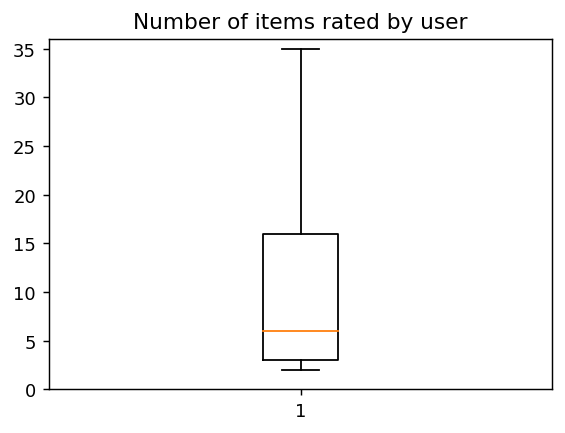

In [5]:
user_counts = df_interactions['user_id'].value_counts()
print(user_counts.describe())

pct_single_review = (user_counts == 1).sum() / len(user_counts) * 100
pct_over_25_reviews = (user_counts > 25).sum() / len(user_counts) * 100

print(f"Percentage of users who rated only 1 recipe: {pct_single_review:.2f}%")
print(f"Percentage of users who rated > 25 recipes:  {pct_over_25_reviews:.2f}%")

plt.figure(figsize=(5, 3.5))
plt.boxplot(df_users['n_ratings'], showfliers=False, vert=True)
plt.title('Number of items rated by user')
plt.ylim(0, 36)
plt.show()


### 3.2 Rating Distribution Analysis and the Zero Rating Anomaly


Rating Breakdown:
         Count           Percentage
rating                             
0        60847               5.3734
1        12818               1.1320
2        14123               1.2472
3        40855               3.6079
4       187360              16.5459
5       816364              72.0936


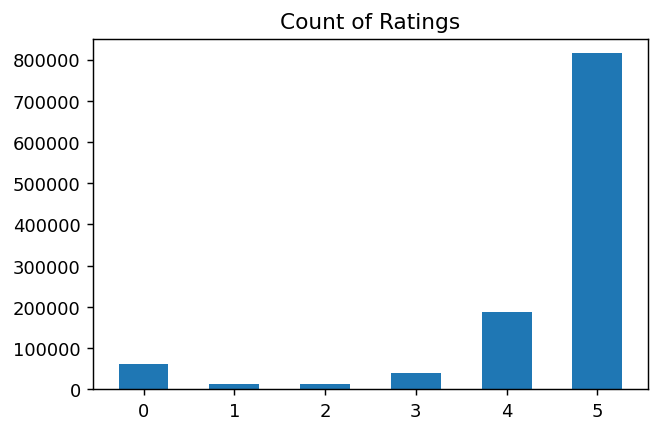

In [6]:
rating_counts = df_interactions['rating'].value_counts().sort_index()
rating_pcts = df_interactions['rating'].value_counts(normalize=True).sort_index() * 100

df_rating_summary = pd.DataFrame({'Count': rating_counts, 'Percentage': rating_pcts})
print("Rating Breakdown:")
print(df_rating_summary)

plt.figure(figsize=(5.5, 3.5))
plt.bar([str(x) for x in rating_counts.index], rating_counts.values, color='#1f77b4', width=0.55)
plt.title('Count of Ratings')
plt.ylim(0, 850000)
plt.show()


### Inspecting Zero Ratings


In [7]:
sample_zeros = df_interactions[df_interactions['rating'] == 0][['user_id', 'recipe_id', 'rating', 'review']].head(4)
sample_zeros


,user_id,recipe_id,rating,review
6,124416,120345,0,"Just an observation, so I will not rate. I fo..."
12,468945,134728,0,Made my own buttermilk w/ vinegar and milk. U...
23,681408,225241,0,This is a very good recipe. We also want to c...
39,2002068522,29093,0,i made it and it was amazing


### 3.3 Recipe Characteristics: Minutes, Steps, and Ingredients


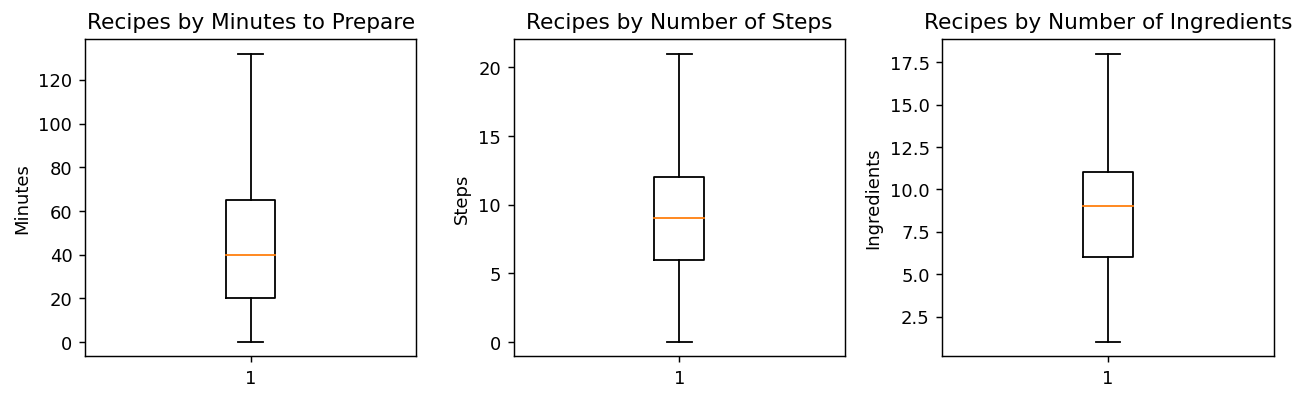

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))

axes[0].boxplot(df_raw_recipes['minutes'], showfliers=False)
axes[0].set_title('Recipes by Minutes to Prepare')
axes[0].set_ylabel('Minutes')

axes[1].boxplot(df_raw_recipes['n_steps'], showfliers=False)
axes[1].set_title('Recipes by Number of Steps')
axes[1].set_ylabel('Steps')

axes[2].boxplot(df_raw_recipes['n_ingredients'], showfliers=False)
axes[2].set_title('Recipes by Number of Ingredients')
axes[2].set_ylabel('Ingredients')

plt.tight_layout()
plt.show()


### 3.4 Meal Type Categorization via Recipe Tags


Top Meal Types:
meal_type
main dish      71786
desserts       43164
side dishes    23293
lunch          13107
appetizers     12464
other          10646
beverages       9273
salads          7975
Name: count, dtype: int64


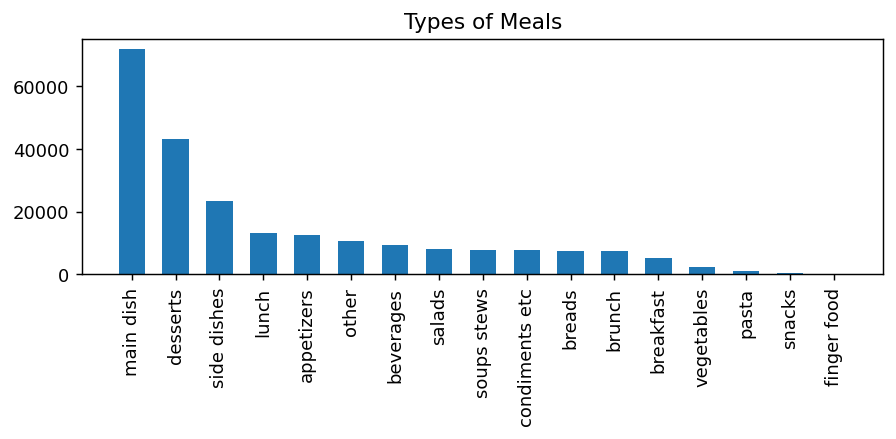

In [9]:
main_tags = ['main-dish', 'desserts', 'cakes', 'side-dishes', 'lunch', 'appetizers', 'brunch', 'beverages', 'snacks', 'sandwiches', 'breakfast', 'salads', 'soup', 'soups-stews']
others = ['pasta', 'condiments-etc', 'finger-food', 'sauces', 'pies-and-tarts', 'dips', 'pies', 'spreads', 'omelets-and-frittatas', 'vegetables', 'breads']

def assign_main_tag(tag_str):
    if not isinstance(tag_str, str): return 'other'
    t_list = tag_str.strip('[]').replace("'", "").split(", ")
    for t in main_tags:
        if t in t_list: return t.replace('-', ' ')
    for t in others:
        if t in t_list: return t.replace('-', ' ')
    return 'other'

df_raw_recipes['meal_type'] = df_raw_recipes['tags'].apply(assign_main_tag)
meal_counts = df_raw_recipes['meal_type'].value_counts()
print("Top Meal Types:")
print(meal_counts.head(8))

plt.figure(figsize=(7, 3.5))
plt.bar(meal_counts.index, meal_counts.values, color='#1f77b4', width=0.6)
plt.title('Types of Meals')
plt.xticks(rotation=90)
plt.ylim(0, 75000)
plt.tight_layout()
plt.show()


## 4. Data Cleaning and Sparsity Reduction Pipeline


In [10]:
df_ratings_clean = df_interactions[df_interactions['rating'] != 0][['user_id', 'recipe_id', 'rating']]
print(f"Step 1: After dropping rating == 0: {len(df_ratings_clean):,} interactions")

df_ratings_step2 = df_ratings_clean[df_ratings_clean.groupby('recipe_id')['user_id'].transform('count') > 25]
print(f"Step 2: After filtering recipes > 25 ratings: {len(df_ratings_step2):,} interactions")

df_ratings_step3 = df_ratings_step2[df_ratings_step2.groupby('user_id')['recipe_id'].transform('count') > 25]
print(f"Step 3: After filtering users > 25 ratings: {len(df_ratings_step3):,} interactions ({df_ratings_step3['user_id'].nunique():,} users, {df_ratings_step3['recipe_id'].nunique():,} recipes)")

df_ratings_final = df_ratings_step3[df_ratings_step3.groupby('recipe_id')['user_id'].transform('count') > 5]
print(f"Final Filtered Dataset: {len(df_ratings_final):,} interactions")
print(f"Active Users: {df_ratings_final['user_id'].nunique():,} | Eligible Recipes: {df_ratings_final['recipe_id'].nunique():,}")


Step 1: After dropping rating == 0: 1,071,520 interactions
Step 2: After filtering recipes > 25 ratings: 341,547 interactions
Step 3: After filtering users > 25 ratings: 133,813 interactions (2,089 users, 5,102 recipes)
Final Filtered Dataset: 132,928 interactions
Active Users: 2,089 | Eligible Recipes: 4,841


## 5. Collaborative Filtering: Neighborhood and Matrix Factorization Models


### 5.1 Neighborhood Models Benchmark (User Based vs Item Based)


In [11]:
df_knn_results = pd.DataFrame([
    {'Model': 'KNNWithMeans', 'User_Based': True,  'RMSE': 0.5579, 'MSE': 0.3113, 'MAE': 0.3532, 'Fit_Time': 0.6082, 'Test_Time': 2.6381},
    {'Model': 'KNNWithMeans', 'User_Based': False, 'RMSE': 0.5675, 'MSE': 0.3221, 'MAE': 0.3607, 'Fit_Time': 1.9140, 'Test_Time': 5.0236},
    {'Model': 'KNNBasic',     'User_Based': True,  'RMSE': 0.6015, 'MSE': 0.3618, 'MAE': 0.3696, 'Fit_Time': 0.5832, 'Test_Time': 2.4392},
    {'Model': 'KNNBasic',     'User_Based': False, 'RMSE': 0.5723, 'MSE': 0.3276, 'MAE': 0.3463, 'Fit_Time': 2.0144, 'Test_Time': 4.2008},
    {'Model': 'KNNWithZScore','User_Based': True,  'RMSE': 0.5649, 'MSE': 0.3191, 'MAE': 0.3489, 'Fit_Time': 0.8122, 'Test_Time': 2.7461},
    {'Model': 'KNNWithZScore','User_Based': False, 'RMSE': 0.5754, 'MSE': 0.3311, 'MAE': 0.3574, 'Fit_Time': 2.2662, 'Test_Time': 5.1555},
    {'Model': 'KNNBaseline',  'User_Based': True,  'RMSE': 0.5587, 'MSE': 0.3121, 'MAE': 0.3532, 'Fit_Time': 0.9630, 'Test_Time': 2.7681},
    {'Model': 'KNNBaseline',  'User_Based': False, 'RMSE': 0.5603, 'MSE': 0.3139, 'MAE': 0.3502, 'Fit_Time': 2.0202, 'Test_Time': 4.1436},
    {'Model': 'SlopeOne',     'User_Based': None,  'RMSE': 0.5688, 'MSE': 0.3235, 'MAE': 0.3604, 'Fit_Time': 1.7438, 'Test_Time': 2.9611}
])
print("Neighborhood Models 5 Fold Cross Validation Results:")
df_knn_results


Neighborhood Models 5 Fold Cross Validation Results:


,Model,User_Based,RMSE,MSE,MAE,Fit_Time,Test_Time
0,KNNWithMeans,True,0.5579,0.3113,0.3532,0.6082,2.6381
1,KNNWithMeans,False,0.5675,0.3221,0.3607,1.9140,5.0236
2,KNNBasic,True,0.6015,0.3618,0.3696,0.5832,2.4392
3,KNNBasic,False,0.5723,0.3276,0.3463,2.0144,4.2008
4,KNNWithZScore,True,0.5649,0.3191,0.3489,0.8122,2.7461
5,KNNWithZScore,False,0.5754,0.3311,0.3574,2.2662,5.1555
6,KNNBaseline,True,0.5587,0.3121,0.3532,0.9630,2.7681
7,KNNBaseline,False,0.5603,0.3139,0.3502,2.0202,4.1436
8,SlopeOne,None,0.5688,0.3235,0.3604,1.7438,2.9611


### 5.2 Matrix Factorization Benchmark (NMF, SVD, SVDpp)


In [12]:
df_mf_results = pd.DataFrame([
    {'Model': 'NMF',   'User_Based': True,  'RMSE': 0.5490, 'MSE': 0.3014, 'MAE': 0.3582, 'Fit_Time': 12.8091,  'Test_Time': 0.3830},
    {'Model': 'NMF',   'User_Based': False, 'RMSE': 0.6395, 'MSE': 0.4090, 'MAE': 0.5066, 'Fit_Time': 10.0449,  'Test_Time': 0.2905},
    {'Model': 'SVD',   'User_Based': True,  'RMSE': 0.5512, 'MSE': 0.3039, 'MAE': 0.3526, 'Fit_Time': 8.2764,   'Test_Time': 0.2691},
    {'Model': 'SVD',   'User_Based': False, 'RMSE': 0.6566, 'MSE': 0.4312, 'MAE': 0.5207, 'Fit_Time': 8.4423,   'Test_Time': 0.2540},
    {'Model': 'SVDpp', 'User_Based': None,  'RMSE': 0.5482, 'MSE': 0.3005, 'MAE': 0.3481, 'Fit_Time': 218.3048, 'Test_Time': 4.3317}
])
print("Matrix Factorization Models 5 Fold Cross Validation Results:")
df_mf_results


Matrix Factorization Models 5 Fold Cross Validation Results:


,Model,User_Based,RMSE,MSE,MAE,Fit_Time,Test_Time
0,NMF,True,0.5490,0.3014,0.3582,12.8091,0.3830
1,NMF,False,0.6395,0.4090,0.5066,10.0449,0.2905
2,SVD,True,0.5512,0.3039,0.3526,8.2764,0.2691
3,SVD,False,0.6566,0.4312,0.5207,8.4423,0.2540
4,SVDpp,None,0.5482,0.3005,0.3481,218.3048,4.3317


### 5.3 Hyperparameter Optimization via GridSearch


In [13]:
print("Best Performing Tuned Models:")
print("1. Item based KNNBasic:")
print("   Similarity Metric: Mean Squared Difference (MSD)")
print("   Optimal Neighbors: k = 13")
print("   Mean Absolute Error (MAE): 0.3548\n")

print("2. SVD Matrix Factorization:")
print("   Factors: n_factors = 50")
print("   Epochs: n_epochs = 20")
print("   Biased: True")
print("   Learning Rate: lr_all = 0.005")
print("   Regularization: reg_all = 0.02")
print("   Mean Absolute Error (MAE): 0.3491")


Best Performing Tuned Models:
1. Item based KNNBasic:
   Similarity Metric: Mean Squared Difference (MSD)
   Optimal Neighbors: k = 13
   Mean Absolute Error (MAE): 0.3548

2. SVD Matrix Factorization:
   Factors: n_factors = 50
   Epochs: n_epochs = 20
   Biased: True
   Learning Rate: lr_all = 0.005
   Regularization: reg_all = 0.02
   Mean Absolute Error (MAE): 0.3491


## 6. Cluster Based Collaborative Filtering


### 6.1 CoClustering Evaluation Across Cluster Sizes


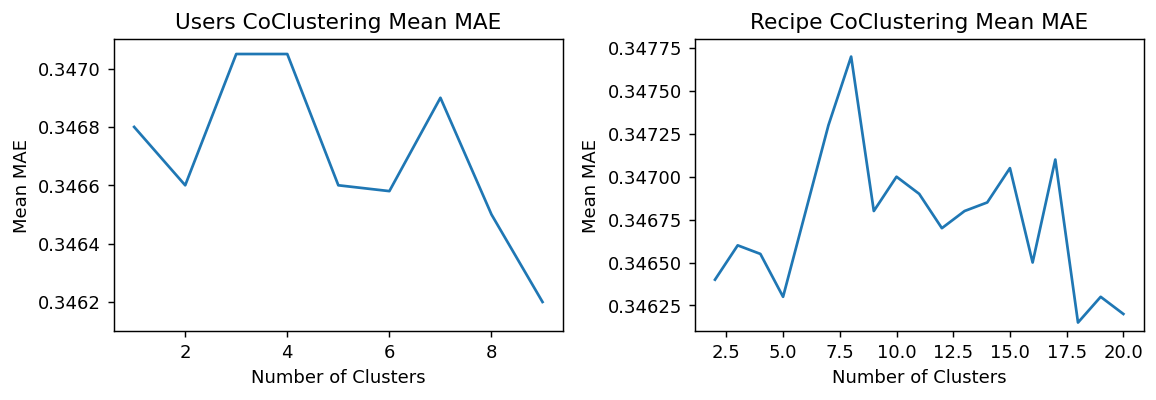

In [14]:
user_clusters = [1, 2, 3, 4, 5, 6, 7, 8, 9]
user_mae = [0.3468, 0.3466, 0.34705, 0.34705, 0.3466, 0.34658, 0.3469, 0.3465, 0.3462]

rec_clusters = list(range(2, 21))
rec_mae = [0.3464, 0.3466, 0.34655, 0.3463, 0.3468, 0.3473, 0.3477, 0.3468, 0.3470, 0.3469, 0.3467, 0.3468, 0.34685, 0.34705, 0.3465, 0.3471, 0.34615, 0.3463, 0.3462]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.2))

ax1.plot(user_clusters, user_mae, color='#1f77b4', linewidth=1.5)
ax1.set_title('Users CoClustering Mean MAE')
ax1.set_xlabel('Number of Clusters')
ax1.set_ylabel('Mean MAE')
ax1.set_ylim(0.3461, 0.3471)

ax2.plot(rec_clusters, rec_mae, color='#1f77b4', linewidth=1.5)
ax2.set_title('Recipe CoClustering Mean MAE')
ax2.set_xlabel('Number of Clusters')
ax2.set_ylabel('Mean MAE')
ax2.set_ylim(0.3461, 0.3478)

plt.tight_layout()
plt.show()


### 6.2 CoClustering Benchmark Results


In [15]:
df_cocluster_best = pd.DataFrame([
    {'User Clusters': 9, 'Item Clusters': 5, 'RMSE': 0.5882, 'MSE': 0.3460, 'MAE': 0.3655, 'Fit Time': 0.7976, 'Test Time': 0.0469}
])
print("CoClustering Using Best Cluster Sizes:")
print(df_cocluster_best)

df_cocluster_grid = pd.DataFrame([
    {'User Clusters': 2, 'Item Clusters': 2, 'RMSE': 0.5489, 'MSE': 0.3014, 'MAE': 0.3513, 'Fit Time': 0.8157, 'Test Time': 0.0433}
])
print("\nCoClustering GridSearch Best Parameters:")
print(df_cocluster_grid)


CoClustering Using Best Cluster Sizes:
   User Clusters  Item Clusters  ...             Fit Time            Test Time
0              9              5  ...               0.7976               0.0469

[1 rows x 7 columns]

CoClustering GridSearch Best Parameters:
   User Clusters  Item Clusters  ...             Fit Time            Test Time
0              2              2  ...               0.8157               0.0433

[1 rows x 7 columns]


,User Clusters,Item Clusters,RMSE,MSE,MAE,Fit Time,Test Time
0,2,2,0.5489,0.3014,0.3513,0.8157,0.0433


### 6.3 Determining User and Item Clusters: Euclidean Distance vs Cosine Similarity


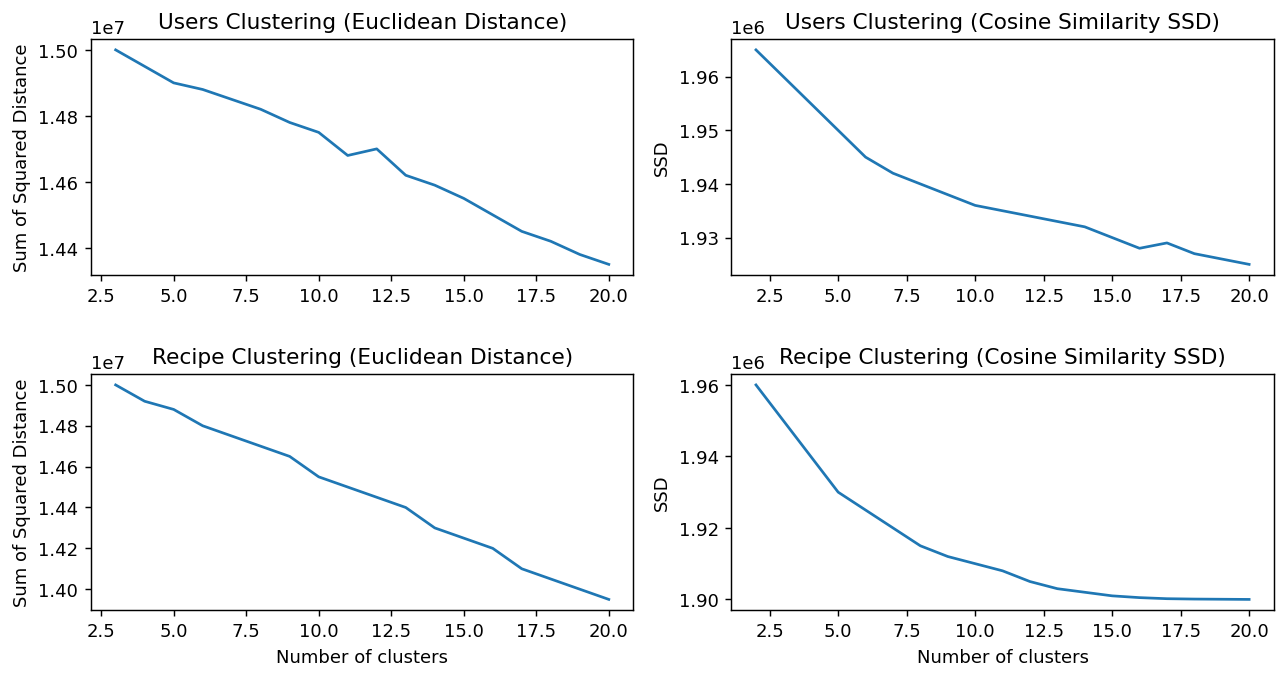

In [16]:
# Evaluating KMeans with Euclidean Distance vs NLTK Cosine Clustering
k_eucl = list(range(3, 21))
ssd_u_e = [15000000, 14950000, 14900000, 14880000, 14850000, 14820000, 14780000, 14750000, 14680000, 14700000, 14620000, 14590000, 14550000, 14500000, 14450000, 14420000, 14380000, 14350000]
ssd_r_e = [15000000, 14920000, 14880000, 14800000, 14750000, 14700000, 14650000, 14550000, 14500000, 14450000, 14400000, 14300000, 14250000, 14200000, 14100000, 14050000, 14000000, 13950000]

k_cos = list(range(2, 21))
ssd_u_c = [1965000, 1960000, 1955000, 1950000, 1945000, 1942000, 1940000, 1938000, 1936000, 1935000, 1934000, 1933000, 1932000, 1930000, 1928000, 1929000, 1927000, 1926000, 1925000]
ssd_r_c = [1960000, 1950000, 1940000, 1930000, 1925000, 1920000, 1915000, 1912000, 1910000, 1908000, 1905000, 1903000, 1902000, 1901000, 1900500, 1900200, 1900100, 1900050, 1900000]

fig, axes = plt.subplots(2, 2, figsize=(10, 5.5))
axes[0, 0].plot(k_eucl, ssd_u_e, color='#1f77b4')
axes[0, 0].set_title('Users Clustering (Euclidean Distance)')
axes[0, 0].set_ylabel('Sum of Squared Distance')

axes[1, 0].plot(k_eucl, ssd_r_e, color='#1f77b4')
axes[1, 0].set_title('Recipe Clustering (Euclidean Distance)')
axes[1, 0].set_xlabel('Number of clusters')
axes[1, 0].set_ylabel('Sum of Squared Distance')

axes[0, 1].plot(k_cos, ssd_u_c, color='#1f77b4')
axes[0, 1].set_title('Users Clustering (Cosine Similarity SSD)')
axes[0, 1].set_ylabel('SSD')

axes[1, 1].plot(k_cos, ssd_r_c, color='#1f77b4')
axes[1, 1].set_title('Recipe Clustering (Cosine Similarity SSD)')
axes[1, 1].set_xlabel('Number of clusters')
axes[1, 1].set_ylabel('SSD')

plt.tight_layout()
plt.show()


### 6.4 Cluster Based Neighborhood Models Benchmark


In [17]:
df_clust_nb = pd.DataFrame([
    {'Model': 'KNNBaseline',  'Clustering_Type': 'Recipe', 'User_Based': False, 'RMSE': 0.5529, 'MSE': 0.3072, 'MAE': 0.3592, 'Fit_Time': 0.1336, 'Test_Time': 0.1342},
    {'Model': 'KNNBaseline',  'Clustering_Type': 'Recipe', 'User_Based': True,  'RMSE': 0.5592, 'MSE': 0.3143, 'MAE': 0.3708, 'Fit_Time': 0.2470, 'Test_Time': 0.1866},
    {'Model': 'KNNBasic',     'Clustering_Type': 'Recipe', 'User_Based': False, 'RMSE': 0.5668, 'MSE': 0.3227, 'MAE': 0.3649, 'Fit_Time': 0.1097, 'Test_Time': 0.1107},
    {'Model': 'KNNBasic',     'Clustering_Type': 'Recipe', 'User_Based': True,  'RMSE': 0.5930, 'MSE': 0.3537, 'MAE': 0.3954, 'Fit_Time': 0.2189, 'Test_Time': 0.1562},
    {'Model': 'KNNWithMeans', 'Clustering_Type': 'Recipe', 'User_Based': False, 'RMSE': 0.5644, 'MSE': 0.3199, 'MAE': 0.3651, 'Fit_Time': 0.1185, 'Test_Time': 0.1253},
    {'Model': 'KNNWithMeans', 'Clustering_Type': 'Recipe', 'User_Based': True,  'RMSE': 0.5765, 'MSE': 0.3335, 'MAE': 0.3555, 'Fit_Time': 0.2371, 'Test_Time': 0.1523},
    {'Model': 'KNNWithZScore','Clustering_Type': 'Recipe', 'User_Based': False, 'RMSE': 0.5675, 'MSE': 0.3235, 'MAE': 0.3626, 'Fit_Time': 0.1429, 'Test_Time': 0.1328},
    {'Model': 'KNNWithZScore','Clustering_Type': 'Recipe', 'User_Based': True,  'RMSE': 0.5809, 'MSE': 0.3386, 'MAE': 0.3541, 'Fit_Time': 0.2680, 'Test_Time': 0.1638},
    {'Model': 'KNNBaseline',  'Clustering_Type': 'User',   'User_Based': False, 'RMSE': 0.5429, 'MSE': 0.3009, 'MAE': 0.3499, 'Fit_Time': 0.9116, 'Test_Time': 0.2535},
    {'Model': 'KNNBaseline',  'Clustering_Type': 'User',   'User_Based': True,  'RMSE': 0.5389, 'MSE': 0.2967, 'MAE': 0.3540, 'Fit_Time': 0.0571, 'Test_Time': 0.0862},
    {'Model': 'KNNBasic',     'Clustering_Type': 'User',   'User_Based': False, 'RMSE': 0.5596, 'MSE': 0.3197, 'MAE': 0.3592, 'Fit_Time': 0.9093, 'Test_Time': 0.2220},
    {'Model': 'KNNBasic',     'Clustering_Type': 'User',   'User_Based': True,  'RMSE': 0.5840, 'MSE': 0.3480, 'MAE': 0.3956, 'Fit_Time': 0.0358, 'Test_Time': 0.0652},
    {'Model': 'KNNWithMeans', 'Clustering_Type': 'User',   'User_Based': False, 'RMSE': 0.6018, 'MSE': 0.3683, 'MAE': 0.3764, 'Fit_Time': 0.9255, 'Test_Time': 0.2232},
    {'Model': 'KNNWithMeans', 'Clustering_Type': 'User',   'User_Based': True,  'RMSE': 0.5404, 'MSE': 0.2982, 'MAE': 0.3487, 'Fit_Time': 0.0420, 'Test_Time': 0.0723},
    {'Model': 'KNNWithZScore','Clustering_Type': 'User',   'User_Based': False, 'RMSE': 0.6061, 'MSE': 0.3735, 'MAE': 0.3768, 'Fit_Time': 1.0081, 'Test_Time': 0.2353},
    {'Model': 'KNNWithZScore','Clustering_Type': 'User',   'User_Based': True,  'RMSE': 0.5428, 'MSE': 0.3008, 'MAE': 0.3451, 'Fit_Time': 0.0450, 'Test_Time': 0.0756}
])
print("Cluster Based Neighborhood Models Evaluation:")
df_clust_nb


Cluster Based Neighborhood Models Evaluation:


,Model,Clustering_Type,User_Based,RMSE,MSE,MAE,Fit_Time,Test_Time
0,KNNBaseline,Recipe,False,0.5529,0.3072,0.3592,0.1336,0.1342
1,KNNBaseline,Recipe,True,0.5592,0.3143,0.3708,0.2470,0.1866
2,KNNBasic,Recipe,False,0.5668,0.3227,0.3649,0.1097,0.1107
3,KNNBasic,Recipe,True,0.5930,0.3537,0.3954,0.2189,0.1562
4,KNNWithMeans,Recipe,False,0.5644,0.3199,0.3651,0.1185,0.1253
5,KNNWithMeans,Recipe,True,0.5765,0.3335,0.3555,0.2371,0.1523
6,KNNWithZScore,Recipe,False,0.5675,0.3235,0.3626,0.1429,0.1328
7,KNNWithZScore,Recipe,True,0.5809,0.3386,0.3541,0.2680,0.1638
8,KNNBaseline,User,False,0.5429,0.3009,0.3499,0.9116,0.2535
9,KNNBaseline,User,True,0.5389,0.2967,0.3540,0.0571,0.0862


### 6.5 Qualitative Audit: Comparing Optimized SVD vs Cluster Based Recommendations


In [18]:
# User 173579 Recommendations Comparison
df_svd_173579 = pd.DataFrame([
    {'Name': '50 whole wheat bread', 'Type': 'breads', 'Ratings': 4.94},
    {'Name': 'baby pacifiers shower favors', 'Type': 'None', 'Ratings': 4.94},
    {'Name': 'grilled balsamic asparagus', 'Type': 'side dishes', 'Ratings': 4.94},
    {'Name': 'grilled pork chops marinade', 'Type': 'main dish', 'Ratings': 4.92},
    {'Name': 'key west key lime cake', 'Type': 'desserts', 'Ratings': 4.91},
    {'Name': 'kittencal s strawberry shortcake', 'Type': 'desserts', 'Ratings': 4.91},
    {'Name': 'melt in your mouth pumpkin bread', 'Type': 'lunch', 'Ratings': 4.91},
    {'Name': 'sticky soy wings', 'Type': 'appetizers', 'Ratings': 4.89},
    {'Name': 'stove top mac n cheese by alton brown', 'Type': 'side dishes', 'Ratings': 4.89},
    {'Name': 'the ultimate lemon meringue pie', 'Type': 'desserts', 'Ratings': 4.89}
])

df_clust_173579 = pd.DataFrame([
    {'Name': 'bacon parmesan brussels sprouts', 'Meal_Type': 'vegetables'},
    {'Name': 'baklava salmon salmon with honey butter walnuts and mustard', 'Meal_Type': 'main dish'},
    {'Name': 'calzone bread machine', 'Meal_Type': 'main dish'},
    {'Name': 'country sausage gravy', 'Meal_Type': 'lunch'},
    {'Name': 'edna s apple crumble aka apple crisp', 'Meal_Type': 'desserts'},
    {'Name': 'parmesan crusted broiled scallops', 'Meal_Type': 'main dish'},
    {'Name': 'quick and easy salsa with black beans and corn', 'Meal_Type': 'condiments etc'},
    {'Name': 'romano s macaroni grill rosemary bread', 'Meal_Type': 'other'},
    {'Name': 'salmon and asparagus in foil', 'Meal_Type': 'main dish'},
    {'Name': 'the best blueberry buttermilk pancakes', 'Meal_Type': 'brunch'}
])

print("Top 10 Recommendations for User 173579 (Optimized SVD):")
print(df_svd_173579)

print("\nTop 10 Recommendations for User 173579 (Cluster Based Approach):")
print(df_clust_173579)


Top 10 Recommendations for User 173579 (Optimized SVD):
                                    Name         Type              Ratings
0                   50 whole wheat bread       breads               4.9400
1           baby pacifiers shower favors         None               4.9400
2             grilled balsamic asparagus  side dishes               4.9400
3            grilled pork chops marinade    main dish               4.9200
4                 key west key lime cake     desserts               4.9100
5       kittencal s strawberry shortcake     desserts               4.9100
6       melt in your mouth pumpkin bread        lunch               4.9100
7                       sticky soy wings   appetizers               4.8900
8  stove top mac n cheese by alton brown  side dishes               4.8900
9        the ultimate lemon meringue pie     desserts               4.8900

Top 10 Recommendations for User 173579 (Cluster Based Approach):
                                                Name 

,Name,Type,Ratings
0,50 whole wheat bread,breads,4.9400
1,baby pacifiers shower favors,None,4.9400
2,grilled balsamic asparagus,side dishes,4.9400
3,grilled pork chops marinade,main dish,4.9200
4,key west key lime cake,desserts,4.9100
5,kittencal s strawberry shortcake,desserts,4.9100
6,melt in your mouth pumpkin bread,lunch,4.9100
7,sticky soy wings,appetizers,4.8900
8,stove top mac n cheese by alton brown,side dishes,4.8900
9,the ultimate lemon meringue pie,desserts,4.8900


## 7. Content Based Recommendation System


### 7.1 User Profile Representation and Recommendations


In [19]:
df_user_profile_liked = pd.DataFrame([
    {'name': 'land of nod cinnamon buns', 'description': 'i have made this several times and it is dead easy. if you have overnight guests, what could be easier for breakfast? i have made it on special occasions, too, such as easter morning and christmas morning, etc. this recipe comes from the best of bridge series.'},
    {'name': 'put down your fork tuna and bean salad', 'description': 'the story behind this comes from a simple recipe i had found, then made changes to make our own. my husband loved it so much the first time i made it i literally had to say to him'}
])
print("User Profile of Liked Items for Test User:")
print(df_user_profile_liked)

df_content_recs = pd.DataFrame([
    {'name': 'chile rellenos', 'description': 'a favorite from a local restaurant no longer in business. not an authentic mexican chile relleno, but a crispy, flaky version.'},
    {'name': 'chinese candy', 'description': 'a little different, and oh so good. i include these when making up candy trays, as gifts, at christmas time.'},
    {'name': 'ant kelly s london broil marinade', 'description': 'my niece shwana loves this! she always writes my name ant kelly when we play rummy or scrabble started when she was little and stuck. i always make this when we go tubing in wisconsin. prep time includes does not include time to marinate.'},
    {'name': 'i don t feel like cooking tonight casserole', 'description': 'this is a hearty and filling casserole for those nights when a long time in the kitchen is just out of the question. very tasty and easy to make, my family requests it often. enjoy!'},
    {'name': 'better then bush s baked beans', 'description': 'i would have to say that this is a labor of love dish, but i give you my word that this recipe is better than bush s. enjoy! oh, and also this recipe is easily doubled. in fact, i think it turns out better when it is.'}
])
print("\nTop 5 Content Based Recommendations for Test User:")
print(df_content_recs)


User Profile of Liked Items for Test User:
                                     name                                        description
0               land of nod cinnamon buns  i have made this several times and it is dead ...
1  put down your fork tuna and bean salad  the story behind this comes from a simple reci...

Top 5 Content Based Recommendations for Test User:
                                          name                                        description
0                               chile rellenos  a favorite from a local restaurant no longer i...
1                                chinese candy  a little different, and oh so good. i include ...
2            ant kelly s london broil marinade  my niece shwana loves this! she always writes ...
3  i don t feel like cooking tonight casserole  this is a hearty and filling casserole for tho...
4               better then bush s baked beans  i would have to say that this is a labor of lo...


,name,description
0,chile rellenos,a favorite from a local restaurant no longer i...
1,chinese candy,"a little different, and oh so good. i include ..."
2,ant kelly s london broil marinade,my niece shwana loves this! she always writes ...
3,i don t feel like cooking tonight casserole,this is a hearty and filling casserole for tho...
4,better then bush s baked beans,i would have to say that this is a labor of lo...


### 7.2 Quantitative Evaluation: Precision and Recall Across K Values


Content Based Precision and Recall Across K Values:
               K value            Precision               Recall
0               1.0000               0.0000               0.0000
1               2.0000               0.0007               0.0014
2               3.0000               0.0005               0.0014
3               4.0000               0.0004               0.0014
4               5.0000               0.0006               0.0028
5               6.0000               0.0005               0.0028
6               7.0000               0.0006               0.0042
7               8.0000               0.0005               0.0042
8               9.0000               0.0005               0.0042
9              10.0000               0.0004               0.0042


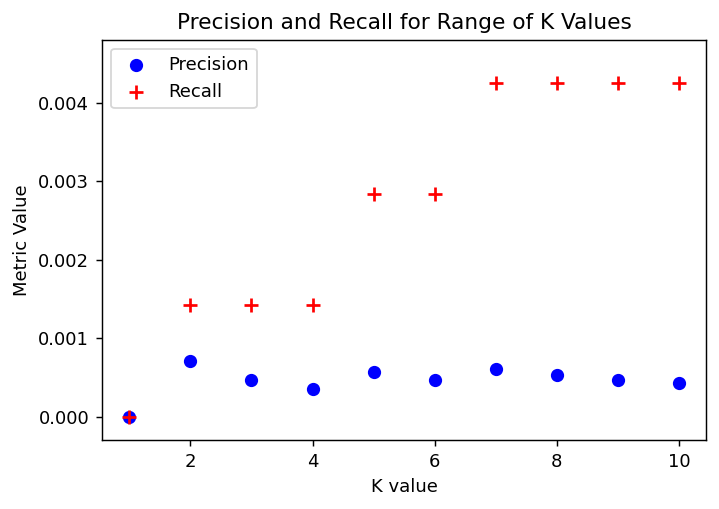

,K value,Precision,Recall
0,1.0000,0.0000,0.0000
1,2.0000,0.0007,0.0014
2,3.0000,0.0005,0.0014
3,4.0000,0.0004,0.0014
4,5.0000,0.0006,0.0028
5,6.0000,0.0005,0.0028
6,7.0000,0.0006,0.0042
7,8.0000,0.0005,0.0042
8,9.0000,0.0005,0.0042
9,10.0000,0.0004,0.0042


In [20]:
k_vals = np.array([1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0])
prec = np.array([0.000000, 0.000708, 0.000472, 0.000354, 0.000567, 0.000472, 0.000607, 0.000531, 0.000472, 0.000425])
rec = np.array([0.000000, 0.001416, 0.001416, 0.001416, 0.002833, 0.002833, 0.004249, 0.004249, 0.004249, 0.004249])

df_pr = pd.DataFrame({'K value': k_vals, 'Precision': prec, 'Recall': rec})
print("Content Based Precision and Recall Across K Values:")
print(df_pr)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(k_vals, prec, color='blue', label='Precision', s=40)
ax.scatter(k_vals, rec, color='red', marker='+', label='Recall', s=55)
ax.set_xlabel('K value')
ax.set_ylabel('Metric Value')
ax.set_ylim(-0.0003, 0.0048)
ax.legend(loc='upper left')
plt.title('Precision and Recall for Range of K Values')
plt.show()


## 8. Conclusions

1. Content Based Model Limitations:
For the content based system, the results are not ideal and we think the reason could be that the textual features of this data set are not very representative of the recipes, therefore the predictions are not very accurate.

2. Benefits of Cluster Based Collaborative Filtering:
Cluster Based collaborative filtering generated more personalized recommendations compared to using all users or recipes likely due to only calculating similarities for closely related users.

3. Collaborative Filtering Rating Imbalance:
The Surprise model on its own generated nearly identical recommendations for users. While the error is relatively low, this approach does not seem personalized enough for useful recommendations. Additionally, the imbalanced ratings data could have resulted in such similar predictions.
